# Exercise 1 - Stream Ciphers

In [16]:
import matplotlib.pyplot as plt
import numpy as np

First of all, we define a function that performs LFSR:

In [17]:
def lfsr(seed, taps, n_bits):
    """
    Generate a pseudorandom sequence using a Linear Feedback Shift Register (LFSR).

    Parameters:
        seed: The initial state of the LFSR as a string of '0' and '1'.
        taps: Positions for feedback XOR operation.
        n_bits: Number of bits to generate.

    Returns:
        list: The generated pseudorandom sequence.
    """
    # Convert seed (string) to a list of integers
    state = [int(bit) for bit in seed]
    length = len(state)

    if max(taps) > length:
        raise ValueError("Taps positions cannot exceed the length of the seed.")

    sequence = []
    
    for _ in range(n_bits):
        # Append the current output (the least significant bit)
        sequence.append(state[-1])
        
        # XOR the tapped positions to determine the feedback bit
        feedback = 0
        for tap in taps:
            feedback ^= state[-(tap + 1)]
        
        # Shift the register and insert the feedback bit
        state = [feedback] + state[:-1]

    return sequence


We also define a function to convert a binary sequence into a bipolar sequence:

In [18]:
def binary_to_bipolar(binary_sequence):
    """
    Converts a binary sequence (0 and 1) into a bipolar sequence (-1 and +1).

    Parameters:
        binary_sequence: A list of binary values (0 and 1).

    Returns:
        list: A list of bipolar values (-1 and +1).
    """
    return [-1 if bit == 0 else 1 for bit in binary_sequence]

We choose an arbitrary seed (0000010100) to initialize the m = 10 cells of the register. The register polynomial description is:
$$        
p(D) = D^{10} + D^3 +1
$$
so the tapped or connected bits are in position 0 and 3.

We then generate the entire M-sequence $v(n)$ of N = 1023 bits, which repeats periodically.

In [19]:
seed = "0000010100"  # Initial seed
taps = [0, 3]  # Tapped bits
N = 1023
n_bits = N    # Number of bits in the sequence
sequence = lfsr(seed, taps, n_bits)
print("Generated Sequence:", sequence)
bipolar = binary_to_bipolar(sequence)
print(f'Bipolar Sequence: {bipolar}')


Generated Sequence: [0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0

Now we plot the first 20 bits of the obtained bipolar sequence.

In [20]:
def plot_bipolar_sequence(bipolar_sequence):

    x = list(range(len(bipolar_sequence) ))  # x-ticks from 0 to 20
    
    # Plot the sequence
    plt.figure(figsize=(10, 4))
    plt.step(x, bipolar_sequence, where='post', label="Bipolar Sequence")
    plt.xticks(range(len(bipolar_sequence)))  # Set x-ticks from 0 to 20
    plt.yticks([-1, 0, 1], labels=['-1', '0', '+1'])  # Set y-ticks
    plt.grid(True, linestyle='--')
    plt.title("Bipolar Sequence (First 20 Bits)")
    plt.xlabel("Index")
    plt.ylabel("Value")
    plt.tight_layout()
    plt.show()


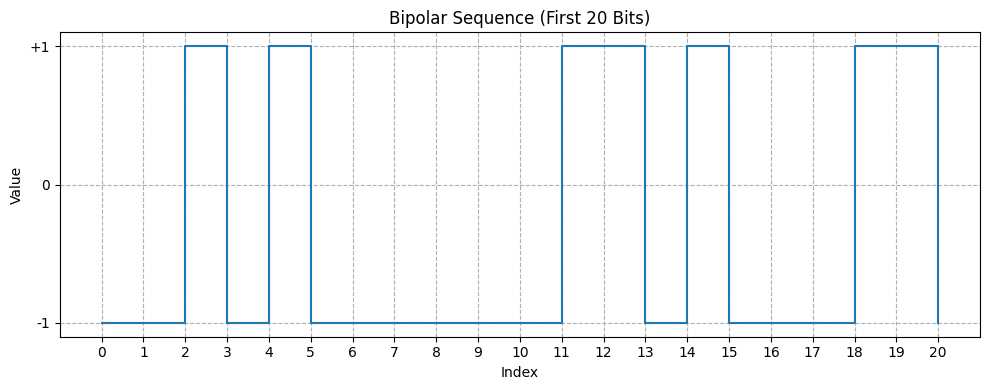

In [21]:
plot_bipolar_sequence(bipolar[:21])

We want to verify that the number of zeros $N_0$ and the number of ones $N_1$ in $v(n)$ are such that:
$$
N_1 = N_0 + 1
$$

In [22]:
N0 = sum([1 if bit == 0 else 0 for bit in sequence])
N1 = sum([1 if bit == 1 else 0 for bit in sequence])
print(f'Number of zeros: {N0}\nNumber of ones: {N1}')

Number of zeros: 511
Number of ones: 512


Let's define a function that counts the number of runs of a certain length in the sequence, distinguishing between runs of zeros and runs of ones:

In [23]:
def count_runs(sequence, run_length):
    """
    Counts the number of runs of a specific length in a binary sequence,
    distinguishing between runs of 0 and runs of 1.

    Parameters:
        sequence: A binary sequence.
        run_length: The target length of the runs to count.

    Returns:
        dict: A dictionary with counts of runs for 0 and 1.
    """
    count_0 = 0  # Count of runs of 0
    count_1 = 0  # Count of runs of 1
    current_run = 1  # Current run length

    for i in range(1, len(sequence)):
        if sequence[i] == sequence[i - 1]:
            current_run += 1
        else:
            # Check if the previous run matches the desired run length
            if current_run == run_length:
                if sequence[i - 1] == 0:
                    count_0 += 1
                else:
                    count_1 += 1
            current_run = 1  # Reset run length for the new run

    # Check the last run
    if current_run == run_length:
        if sequence[-1] == 0:
            count_0 += 1
        else:
            count_1 += 1

    return {'0': count_0, '1': count_1}

We compute a table to check if the values of $\mathcal{N}_i$, $\mathcal{N}_i(0)$ and $\mathcal{N}_i(1)$ (number of runs of length
i, number of runs of zeros of length i, number of runs of ones of length i in $v(n)$) satisfy the ideal properties.

In [24]:
data = []
rows = []
columns = ['Runs of 0s', 'Runs of 1s', 'Total Runs']

for length in range(N):
    runs = count_runs(sequence, length + 1)
    if runs['0'] != 0 or runs['1'] != 0:
        data.append([runs['0'], runs['1'], runs['0'] + runs['1']])
        rows.append(f'Lenght {length + 1}')

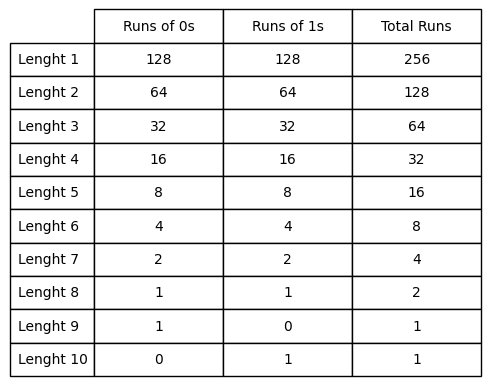

In [25]:
fig, ax = plt.subplots(figsize=(5, 2))
ax.axis('off')

table = plt.table(cellText=data, colLabels=columns, rowLabels=rows, loc='center', cellLoc='center')
table.scale(1, 2)

plt.show()

We define a function to compute the autocorrelation of the bipolar sequence:

In [26]:
def autocorrelation(bipolar_sequence, tau):
    """
    Computes the autocorrelation of a bipolar sequence 
    with respect to a cyclic shift of tau bits.

    Parameters:
        bipolar_sequence: A bipolar sequence.
        tau: The number of bits to shift.

    Returns:
        R: The value of autocorrelation.
    """
    shifted_sequence = bipolar_sequence[tau:] + bipolar_sequence[:tau]
    R = sum([bipolar_sequence[i] * shifted_sequence[i] for i in range(len(bipolar_sequence))])

    return R

We then compute and plot the periodic autocorrelation function $R(\tau)$ with $-\frac{N-1}{2} \le \tau \le \frac{N-1}{2}$.

In [27]:
R = []
for tau in range(int(-(N-1)/2), int((N-1)/2 + 1)):
    R.append(autocorrelation(bipolar, tau))

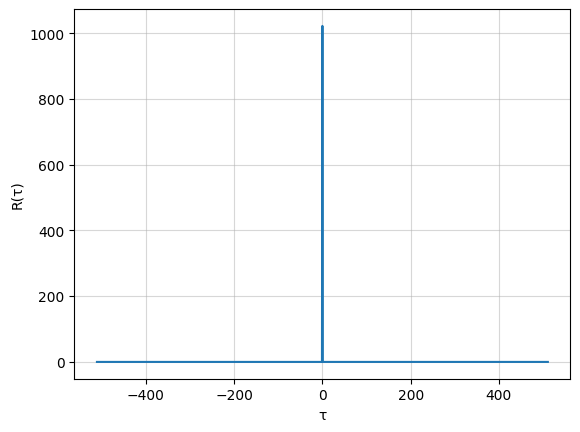

In [28]:
plt.plot(range(int(-(N-1)/2), int((N-1)/2 + 1)), R)
plt.grid(True, alpha=0.5)
plt.xlabel('\u03c4')
plt.ylabel('R(\u03c4)')

plt.show()

## Breaking a linear LFSR

We start by defining a function that solves binary linear systems in GF(2):

In [29]:
def solve_binary_linear_system(A, b):
    """
    Solves the binary linear system A x = b in GF(2).

    Parameters:
        A: Coefficient matrix (binary).
        b: Result vector (binary).
        
    Returns:
        x: Solution vector (binary).
    """
    # Convert inputs to numpy arrays and ensure binary
    A = np.array(A) % 2
    b = np.array(b) % 2

    # Get the number of rows and columns in A
    n, m = A.shape

    # Augment A with b (A | b)
    Ab = np.hstack((A, b.reshape(-1, 1)))

    # Gaussian elimination in GF(2)
    for col in range(min(n, m)):
        # Find pivot (ensure non-zero in current column)
        for row in range(col, n):
            if Ab[row, col] == 1:
                # Swap rows if necessary
                Ab[[col, row]] = Ab[[row, col]]
                break
        else:
            # No pivot found, continue to the next column
            continue
        
        # Eliminate other rows in this column
        for row in range(n):
            if row != col and Ab[row, col] == 1:
                Ab[row] ^= Ab[col]  # XOR operation (binary subtraction)

    # Extract solution (if possible)
    x = Ab[:, -1]  # The last column is the augmented result vector

    # Verify solution
    if not np.array_equal(np.dot(A, x) % 2, b):
        raise ValueError("No solution exists or the system is inconsistent.")

    return x

By a chosen plaintext attack, we manage to intercept this portion of the key:

In [30]:
key_portion = '1010100010000001101010010111011000101110'

Let's define a function that, given the key portion and a certain number of cells m, computes the polynomial description of the LFSR:

In [31]:
def plaintext_attack(key, m):
    """
    Computes the primitive polynomial of the LFSR, given the key and the number of cells m.

    Parameters:
        key: The key or a portion of it.
        m: The number of cells.
    
    Returns:
        x: The coefficients of the primitive polynomial (empty vector if there is no solution).
    """
    b = [int(key[i + m]) for i in range(m)]
    A = []
    for i in range(m):
        A.append([int(key[k + i]) for k in range(m)])
    
    try:
        # Attempt to solve the system
        x = solve_binary_linear_system(A, b)
        return x
    except ValueError as e:
        return np.array([])


Now we try to break the LFSR by calculating the polynomial description for an increasing number of cells, starting from m = 3.

For every polynomial found we compute a sequence of 40 bits and compare it with the key portion we have.
If the two sequences are equal, then we have found the correct primitive polynomial.

In [32]:
for m in range(3,21):
    x = plaintext_attack(key_portion, m)
    print(f'Soluzion for m={m}: {x}')
    
    if x.size != 0:
        seed = key_portion[:m][::-1]
        taps = np.flatnonzero(x)
        s = lfsr(seed, taps, len(key_portion))

        if sum([1 if s[i] != int(key_portion[i]) else 0 for i in range(len(key_portion))]) == 0:
            print(f'\tThis is the correct solution!')
            break


Soluzion for m=3: [0 1 0]
Soluzion for m=4: []
Soluzion for m=5: [0 1 0 1 0]
Soluzion for m=6: [1 0 0 0 1 0]
Soluzion for m=7: [0 1 0 0 0 1 0]
Soluzion for m=8: []
Soluzion for m=9: [1 0 1 0 1 0 0 0 1]
Soluzion for m=10: [1 1 0 1 1 1 1 0 0 1]
Soluzion for m=11: [1 1 0 0 0 1 1 1 1 1 1]
Soluzion for m=12: [1 0 1 1 1 1 0 1 1 0 0 1]
Soluzion for m=13: []
Soluzion for m=14: [0 0 0 0 1 0 1 1 1 1 0 0 0 0]
Soluzion for m=15: [1 0 1 1 1 0 0 0 0 1 1 1 1 0 0]
Soluzion for m=16: [0 1 0 1 1 1 0 0 0 0 1 1 1 1 0 0]
Soluzion for m=17: []
Soluzion for m=18: []
Soluzion for m=19: [1 1 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0]
	This is the correct solution!


Finally, now that we have the correct polynomial description of the LFSR, we generate the next 20 bits of the key.

In [33]:
# Next 20 bits of the sequence
next_seq = lfsr(seed, taps, len(key_portion) + 20)
next_seq = next_seq[-20:]
print(f'The next 20 bits of the key are: {next_seq}')

The next 20 bits of the key are: [0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0]
